# Temporal Protein Classification with Vanilla RNN

## Στόχος
Διάγνωση **Healthy / Adenoma / Cancer** με βάση temporal protein profiles (T0→T1)

## Αρχιτεκτονική
**1D-CNN → Vanilla RNN → Attention → Classifier**

## Τι είναι το Vanilla RNN;
Το απλούστερο Recurrent Neural Network:
- Μια απλή εξίσωση: `h_t = tanh(W_hh · h_{t-1} + W_xh · x_t + b)`
- Λιγότερες παράμετροι από LSTM/GRU
- Κατάλληλο για μικρές sequences (όπως 2 timepoints)

---
# ΜΕΡΟΣ 1: SETUP & IMPORTS
---

In [ ]:
# Imports
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.impute import SimpleImputer
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

# Device selection
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f"="*50)
print(f"Using device: {device}")
if torch.cuda.is_available():
    print(f"GPU: {torch.cuda.get_device_name(0)}")
print(f"="*50)

# Reproducibility
def set_seed(seed=42):
    """Set seed for reproducibility"""
    np.random.seed(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

set_seed(42)
print("\n✓ Setup complete!")

Using device: cpu

✓ Setup complete!


---
# ΜΕΡΟΣ 2: CONFIGURATION
---

Όλες οι hyperparameters σε ένα μέρος για εύκολη τροποποίηση.

In [ ]:
class Config:
    """
    Configuration class - Όλες οι hyperparameters εδώ
    """
    # === Random Seed ===
    RANDOM_SEED = 42

    # === Data ===
    N_FOLDS = 5                    # Cross-validation folds
    N_TOP_FEATURES = 50            # Πόσες πρωτεΐνες να κρατήσουμε

    # === Model Architecture ===
    # CNN
    CNN_FILTERS = 32               # Αριθμός filters στο CNN
    CNN_KERNEL_SIZE = 5            # Kernel size

    # RNN
    RNN_HIDDEN_SIZE = 32           # Hidden size του RNN
    RNN_NUM_LAYERS = 1             # Αριθμός RNN layers
    RNN_BIDIRECTIONAL = True       # Bidirectional RNN

    # Attention
    ATTENTION_DIM = 32             # Attention dimension

    # Regularization
    DROPOUT = 0.5                  # Dropout rate

    # === Training ===
    BATCH_SIZE = 8                 # Batch size
    LEARNING_RATE = 1e-4           # Learning rate (μικρό για stability)
    WEIGHT_DECAY = 1e-3            # L2 regularization
    EPOCHS = 100                   # Max epochs
    PATIENCE = 15                  # Early stopping patience

    # === Device ===
    DEVICE = device

# Print configuration
print("Configuration:")
print(f"  Features: {Config.N_TOP_FEATURES}")
print(f"  RNN Hidden: {Config.RNN_HIDDEN_SIZE}")
print(f"  Bidirectional: {Config.RNN_BIDIRECTIONAL}")
print(f"  Dropout: {Config.DROPOUT}")
print(f"  Learning Rate: {Config.LEARNING_RATE}")
print(f"  Cross-validation Folds: {Config.N_FOLDS}")
print("\n✓ Configuration loaded!")

Configuration:
  Features: 50
  RNN Hidden: 32
  Bidirectional: True
  Dropout: 0.5
  Learning Rate: 0.0001
  Cross-validation Folds: 5

✓ Configuration loaded!


---
# ΜΕΡΟΣ 3: DATA LOADING
---

Φόρτωση των Excel αρχείων και δημιουργία του dataset.

In [ ]:
# ╔══════════════════════════════════════════════════════════════╗
# ║  ΑΛΛΑΞΕ ΑΥΤΑ ΤΑ PATHS ΣΤΑ ΔΙΚΑ ΣΟΥ ΑΡΧΕΙΑ                   ║
# ╚══════════════════════════════════════════════════════════════╝

SAMPLES_PATH = '/content/DIOPTRA_Samples_list_Oncology.xlsx'
PROTEINS_PATH = '/content/DIOPTRA_Protein_results_Oncology.xlsx'

In [ ]:
def load_data(samples_path, proteins_path, include_t00=True):
    """
    Φορτώνει και προετοιμάζει τα δεδομένα.

    Parameters:
    -----------
    samples_path : str
        Path στο αρχείο με τα sample metadata
    proteins_path : str
        Path στο αρχείο με τις τιμές πρωτεϊνών
    include_t00 : bool
        Αν θα συμπεριλάβουμε τα single-timepoint samples (T00)

    Returns:
    --------
    X : np.ndarray
        Shape (n_samples, 2, n_proteins)
    y : np.ndarray
        Labels
    protein_names : list
        Ονόματα πρωτεϊνών
    label_encoder : LabelEncoder
        Fitted encoder
    """
    print("Loading data...")
    print("="*50)

    # Load Excel files
    samples = pd.read_excel(samples_path)
    proteins = pd.read_excel(proteins_path)

    print(f"Samples file: {len(samples)} rows")
    print(f"Proteins file: {len(proteins)} rows, {len(proteins.columns)-1} proteins")

    # Merge data
    data = samples.merge(proteins, on='SampleID')

    # Get protein column names
    protein_cols = [c for c in proteins.columns if c != 'SampleID']

    # === Create paired samples (T0 → T1) ===
    print("\nCreating paired samples...")

    t0_data = data[data['Timepoint'] == 'T0'].copy()
    t1_data = data[data['Timepoint'] == 'T1'].copy()

    # Patient ID extraction
    t0_data['PatientID'] = t0_data['SampleID']
    t1_data['PatientID'] = t1_data['SampleID'].str.replace('-F', '', regex=False)

    # Merge T0 and T1
    paired = t0_data.merge(
        t1_data[['PatientID'] + protein_cols],
        on='PatientID',
        suffixes=('_T0', '_T1')
    )
    print(f"  Paired samples (T0→T1): {len(paired)}")

    # === Add T00 samples (single timepoint) ===
    if include_t00:
        t00_data = data[data['Timepoint'] == 'T00'].copy()

        # Duplicate as T0 and T1 (no temporal change)
        for col in protein_cols:
            t00_data[f'{col}_T0'] = t00_data[col]
            t00_data[f'{col}_T1'] = t00_data[col]
        t00_data['PatientID'] = t00_data['SampleID']

        # Combine
        cols_needed = ['PatientID', 'Group'] + [f'{c}_T0' for c in protein_cols] + [f'{c}_T1' for c in protein_cols]
        combined = pd.concat([paired[cols_needed], t00_data[cols_needed]], ignore_index=True)
        print(f"  Single timepoint (T00): {len(t00_data)}")
        print(f"  Total samples: {len(combined)}")
    else:
        combined = paired

    # === Remove NAA class (too few samples) ===
    combined = combined[combined['Group'] != 'NAA']
    print(f"  After removing NAA: {len(combined)}")

    # === Create numpy arrays ===
    X_T0 = combined[[f'{c}_T0' for c in protein_cols]].values
    X_T1 = combined[[f'{c}_T1' for c in protein_cols]].values
    X = np.stack([X_T0, X_T1], axis=1)  # Shape: (n_samples, 2, n_proteins)

    # === Encode labels ===
    label_encoder = LabelEncoder()
    y = label_encoder.fit_transform(combined['Group'].values)

    # === Print class distribution ===
    print(f"\nClass distribution:")
    for i, cls in enumerate(label_encoder.classes_):
        count = (y == i).sum()
        pct = count / len(y) * 100
        print(f"  {cls}: {count} samples ({pct:.1f}%)")

    print(f"\nFinal shapes:")
    print(f"  X: {X.shape} (samples, timepoints, proteins)")
    print(f"  y: {y.shape}")

    return X, y, protein_cols, label_encoder

In [ ]:
# Load the data
X_raw, y, protein_names, label_encoder = load_data(SAMPLES_PATH, PROTEINS_PATH)
class_names = list(label_encoder.classes_)

print("\n" + "="*50)
print("✓ Data loaded successfully!")
print(f"  Classes: {class_names}")

Loading data...
Samples file: 88 rows
Proteins file: 88 rows, 368 proteins

Creating paired samples...
  Paired samples (T0→T1): 24
  Single timepoint (T00): 40
  Total samples: 64
  After removing NAA: 62

Class distribution:
  AA: 27 samples (43.5%)
  CRC: 16 samples (25.8%)
  Healthy: 19 samples (30.6%)

Final shapes:
  X: (62, 2, 368) (samples, timepoints, proteins)
  y: (62,)

✓ Data loaded successfully!
  Classes: ['AA', 'CRC', 'Healthy']


---
# ΜΕΡΟΣ 4: DATA PREPROCESSING
---

1. Handle NaN values
2. Feature selection
3. Normalization

### 4.1 Handle NaN Values

In [ ]:
def handle_nan_values(X, protein_names):
    """
    Χειρίζεται τα NaN values:
    1. Αφαιρεί πρωτεΐνες που έχουν μόνο NaN
    2. Κάνει imputation με median στα υπόλοιπα NaN

    Parameters:
    -----------
    X : np.ndarray
        Shape (n_samples, n_timepoints, n_proteins)
    protein_names : list
        Ονόματα πρωτεϊνών

    Returns:
    --------
    X_clean : np.ndarray
        Cleaned data
    clean_protein_names : list
        Updated protein names
    """
    print("Handling NaN values...")
    print("="*50)

    n_samples, n_timepoints, n_proteins = X.shape
    total_nan = np.isnan(X).sum()
    print(f"  Total NaN values: {total_nan}")
    print(f"  Original shape: {X.shape}")

    if total_nan == 0:
        print("  No NaN values found!")
        return X, protein_names

    # Step 1: Find proteins with ALL NaN values
    valid_protein_mask = ~np.all(np.isnan(X), axis=(0, 1))
    n_all_nan = (~valid_protein_mask).sum()
    print(f"  Proteins with ALL NaN (removed): {n_all_nan}")

    # Remove all-NaN proteins
    X = X[:, :, valid_protein_mask]
    protein_names = [p for p, valid in zip(protein_names, valid_protein_mask) if valid]

    print(f"  Shape after removing all-NaN proteins: {X.shape}")

    # Step 2: Impute remaining NaN with median
    n_samples, n_timepoints, n_proteins = X.shape
    X_imputed = np.zeros_like(X)

    imputer = SimpleImputer(strategy='median')

    for t in range(n_timepoints):
        X_imputed[:, t, :] = imputer.fit_transform(X[:, t, :])

    remaining_nan = np.isnan(X_imputed).sum()
    print(f"  NaN after imputation: {remaining_nan}")
    print(f"  Final shape: {X_imputed.shape}")

    return X_imputed, protein_names

In [ ]:
# Apply NaN handling
X_clean, protein_names = handle_nan_values(X_raw, protein_names)
print("\n✓ NaN handling complete!")

Handling NaN values...
  Total NaN values: 496
  Original shape: (62, 2, 368)
  Proteins with ALL NaN (removed): 4
  Shape after removing all-NaN proteins: (62, 2, 364)
  NaN after imputation: 0
  Final shape: (62, 2, 364)

✓ NaN handling complete!


### 4.2 Feature Selection

In [ ]:
def select_top_features(X, y, protein_names, n_features=50):
    """
    Επιλέγει τις top-K πρωτεΐνες με βάση ANOVA F-score.

    Γιατί feature selection:
    - 368 features με 62 samples = overfitting
    - Κρατάμε μόνο τις πιο discriminative

    Parameters:
    -----------
    X : np.ndarray
        Shape (n_samples, n_timepoints, n_proteins)
    y : np.ndarray
        Labels
    protein_names : list
        Ονόματα πρωτεϊνών
    n_features : int
        Πόσα features να κρατήσουμε

    Returns:
    --------
    X_selected : np.ndarray
        Selected features
    selected_proteins : list
        Names of selected proteins
    selector : SelectKBest
        Fitted selector
    """
    print("Feature Selection...")
    print("="*50)

    # Use T0 for feature selection
    X_t0 = X[:, 0, :]

    # Adjust n_features if needed
    n_available = X_t0.shape[1]
    n_features = min(n_features, n_available)
    print(f"  Available proteins: {n_available}")
    print(f"  Selecting top: {n_features}")

    # ANOVA F-test
    selector = SelectKBest(f_classif, k=n_features)
    selector.fit(X_t0, y)

    # Get selected indices
    selected_mask = selector.get_support()
    selected_indices = np.where(selected_mask)[0]

    # Apply to both timepoints
    X_selected = X[:, :, selected_indices]

    # Get selected protein names
    selected_proteins = [protein_names[i] for i in selected_indices]

    # Get scores for ranking
    scores = selector.scores_[selected_indices]
    protein_scores = sorted(zip(selected_proteins, scores), key=lambda x: x[1], reverse=True)

    print(f"\n  Top 10 discriminative proteins:")
    for i, (prot, score) in enumerate(protein_scores[:10]):
        print(f"    {i+1}. {prot:<15} (F-score: {score:.2f})")

    print(f"\n  Final shape: {X_selected.shape}")

    return X_selected, selected_proteins, selector, selected_indices

In [ ]:
# Apply feature selection
X_selected, selected_proteins, feature_selector, selected_indices = select_top_features(
    X_clean, y, protein_names, n_features=Config.N_TOP_FEATURES
)
print("\n✓ Feature selection complete!")

Feature Selection...
  Available proteins: 364
  Selecting top: 50

  Top 10 discriminative proteins:
    1. MMP12           (F-score: 12.11)
    2. AREG            (F-score: 11.87)
    3. ITGAV           (F-score: 7.53)
    4. EDA2R           (F-score: 7.33)
    5. HS6ST1          (F-score: 7.00)
    6. APEX1           (F-score: 6.86)
    7. L1CAM           (F-score: 6.82)
    8. PRKRA           (F-score: 6.75)
    9. VEGFC           (F-score: 6.67)
    10. WFDC2           (F-score: 6.32)

  Final shape: (62, 2, 50)

✓ Feature selection complete!


### 4.3 Normalization

In [ ]:
def normalize_data(X):
    """
    Κανονικοποιεί τα δεδομένα (mean=0, std=1).

    Parameters:
    -----------
    X : np.ndarray
        Shape (n_samples, n_timepoints, n_features)

    Returns:
    --------
    X_normalized : np.ndarray
        Normalized data
    scaler : StandardScaler
        Fitted scaler
    """
    print("Normalizing data...")
    print("="*50)

    n_samples, n_timepoints, n_features = X.shape

    # Flatten to 2D for normalization
    X_flat = X.reshape(-1, n_features)

    # Normalize
    scaler = StandardScaler()
    X_flat_scaled = scaler.fit_transform(X_flat)

    # Clip extreme values (για numerical stability)
    X_flat_scaled = np.clip(X_flat_scaled, -5, 5)

    # Reshape back
    X_normalized = X_flat_scaled.reshape(n_samples, n_timepoints, n_features)

    print(f"  Original range: [{X.min():.2f}, {X.max():.2f}]")
    print(f"  Normalized range: [{X_normalized.min():.2f}, {X_normalized.max():.2f}]")
    print(f"  Mean: {X_normalized.mean():.4f}")
    print(f"  Std: {X_normalized.std():.4f}")

    return X_normalized, scaler

In [ ]:
# Apply normalization
X, scaler = normalize_data(X_selected)
print("\n✓ Normalization complete!")
print(f"\nFinal data shape: {X.shape}")
print(f"Any NaN: {np.isnan(X).any()}")

Normalizing data...
  Original range: [-5.41, 8.96]
  Normalized range: [-5.00, 3.85]
  Mean: 0.0000
  Std: 0.9999

✓ Normalization complete!

Final data shape: (62, 2, 50)
Any NaN: False


---
# ΜΕΡΟΣ 5: DATASET CLASS
---

PyTorch Dataset για τα 3 modes: temporal, static, delta

In [ ]:
class ProteinDataset(Dataset):
    """
    PyTorch Dataset για temporal protein data.

    Modes:
    - 'temporal': [T0, T1] - πλήρης χρονική πληροφορία
    - 'static': [T0] μόνο - baseline
    - 'delta': [T1-T0] - μόνο η αλλαγή
    """

    def __init__(self, X, y, mode='temporal'):
        """
        Parameters:
        -----------
        X : np.ndarray
            Shape (n_samples, 2, n_features)
        y : np.ndarray
            Labels
        mode : str
            'temporal', 'static', or 'delta'
        """
        self.mode = mode
        self.y = torch.LongTensor(y)

        if mode == 'temporal':
            # Both timepoints: (n_samples, 2, n_features)
            self.X = torch.FloatTensor(X)
        elif mode == 'static':
            # Only T0: (n_samples, 1, n_features)
            self.X = torch.FloatTensor(X[:, 0:1, :])
        elif mode == 'delta':
            # T1 - T0: (n_samples, 1, n_features)
            delta = X[:, 1, :] - X[:, 0, :]
            self.X = torch.FloatTensor(delta[:, np.newaxis, :])
        else:
            raise ValueError(f"Unknown mode: {mode}. Use 'temporal', 'static', or 'delta'")

    def __len__(self):
        return len(self.y)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]


# Test dataset
print("Testing Dataset class...")
for mode in ['temporal', 'static', 'delta']:
    ds = ProteinDataset(X, y, mode=mode)
    x_sample, y_sample = ds[0]
    print(f"  {mode:10s}: X shape = {x_sample.shape}")

print("\n✓ Dataset class ready!")

Testing Dataset class...
  temporal  : X shape = torch.Size([2, 50])
  static    : X shape = torch.Size([1, 50])
  delta     : X shape = torch.Size([1, 50])

✓ Dataset class ready!


---
# ΜΕΡΟΣ 6: VANILLA RNN MODEL
---

Υλοποίηση του Vanilla RNN model.

### 6.1 Vanilla RNN Cell (Educational Implementation)

In [ ]:
class VanillaRNNCell(nn.Module):
    """
    Vanilla RNN Cell - Educational Implementation

    Εξίσωση:
    h_t = tanh(W_ih · x_t + W_hh · h_{t-1} + b)

    Όπου:
    - x_t: input στο χρόνο t
    - h_{t-1}: hidden state από το προηγούμενο βήμα
    - W_ih: weights για το input
    - W_hh: weights για το hidden state
    - b: bias
    - tanh: activation function
    """

    def __init__(self, input_size, hidden_size):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size

        # Weights
        self.W_ih = nn.Linear(input_size, hidden_size)   # Input to hidden
        self.W_hh = nn.Linear(hidden_size, hidden_size)  # Hidden to hidden

    def forward(self, x, h_prev):
        """
        Forward pass για ένα timestep.

        Parameters:
        -----------
        x : torch.Tensor
            Input at time t, shape (batch, input_size)
        h_prev : torch.Tensor
            Previous hidden state, shape (batch, hidden_size)

        Returns:
        --------
        h_new : torch.Tensor
            New hidden state, shape (batch, hidden_size)
        """
        # h_t = tanh(W_ih · x_t + W_hh · h_{t-1})
        h_new = torch.tanh(self.W_ih(x) + self.W_hh(h_prev))

        return h_new


# Test
print("Testing VanillaRNNCell...")
cell = VanillaRNNCell(input_size=32, hidden_size=16)
x = torch.randn(4, 32)  # batch=4, input=32
h = torch.zeros(4, 16)  # initial hidden state
h_new = cell(x, h)
print(f"  Input: {x.shape}")
print(f"  Hidden: {h.shape} → {h_new.shape}")
print("✓ VanillaRNNCell works!")

Testing VanillaRNNCell...
  Input: torch.Size([4, 32])
  Hidden: torch.Size([4, 16]) → torch.Size([4, 16])
✓ VanillaRNNCell works!


### 6.2 Full Vanilla RNN Layer

In [ ]:
class VanillaRNN(nn.Module):
    """
    Complete Vanilla RNN Layer.

    Επεξεργάζεται ολόκληρη την ακολουθία και επιστρέφει
    τα hidden states για κάθε timestep.
    """

    def __init__(self, input_size, hidden_size, num_layers=1,
                 bidirectional=False, dropout=0.0):
        super().__init__()

        self.input_size = input_size
        self.hidden_size = hidden_size
        self.num_layers = num_layers
        self.bidirectional = bidirectional
        self.num_directions = 2 if bidirectional else 1

        # RNN Cells for each layer and direction
        self.cells_forward = nn.ModuleList()
        self.cells_backward = nn.ModuleList()

        for layer in range(num_layers):
            layer_input_size = input_size if layer == 0 else hidden_size * self.num_directions

            self.cells_forward.append(VanillaRNNCell(layer_input_size, hidden_size))

            if bidirectional:
                self.cells_backward.append(VanillaRNNCell(layer_input_size, hidden_size))

        self.dropout = nn.Dropout(dropout) if dropout > 0 else None

    def forward(self, x, h_0=None):
        """
        Forward pass.

        Parameters:
        -----------
        x : torch.Tensor
            Input sequence, shape (batch, seq_len, input_size)
        h_0 : torch.Tensor, optional
            Initial hidden state

        Returns:
        --------
        output : torch.Tensor
            Hidden states for all timesteps, shape (batch, seq_len, hidden_size * num_directions)
        h_n : torch.Tensor
            Final hidden state
        """
        batch_size, seq_len, _ = x.shape

        # Initialize hidden state
        if h_0 is None:
            h_0 = torch.zeros(self.num_layers * self.num_directions,
                             batch_size, self.hidden_size, device=x.device)

        # Process each layer
        current_input = x
        final_hidden = []

        for layer in range(self.num_layers):
            # Forward direction
            h_forward = h_0[layer * self.num_directions]
            outputs_forward = []

            for t in range(seq_len):
                h_forward = self.cells_forward[layer](current_input[:, t, :], h_forward)
                outputs_forward.append(h_forward)

            outputs_forward = torch.stack(outputs_forward, dim=1)  # (batch, seq_len, hidden)
            final_hidden.append(h_forward)

            # Backward direction
            if self.bidirectional:
                h_backward = h_0[layer * self.num_directions + 1]
                outputs_backward = []

                for t in range(seq_len - 1, -1, -1):
                    h_backward = self.cells_backward[layer](current_input[:, t, :], h_backward)
                    outputs_backward.append(h_backward)

                outputs_backward = torch.stack(outputs_backward[::-1], dim=1)
                final_hidden.append(h_backward)

                # Concatenate forward and backward
                layer_output = torch.cat([outputs_forward, outputs_backward], dim=2)
            else:
                layer_output = outputs_forward

            # Apply dropout between layers
            if self.dropout is not None and layer < self.num_layers - 1:
                layer_output = self.dropout(layer_output)

            current_input = layer_output

        output = current_input
        h_n = torch.stack(final_hidden, dim=0)

        return output, h_n


# Test
print("\nTesting VanillaRNN...")
rnn = VanillaRNN(input_size=32, hidden_size=16, bidirectional=True)
x = torch.randn(4, 10, 32)  # batch=4, seq_len=10, input=32
output, h_n = rnn(x)
print(f"  Input: {x.shape}")
print(f"  Output: {output.shape}")
print(f"  Final hidden: {h_n.shape}")
print("✓ VanillaRNN works!")


Testing VanillaRNN...
  Input: torch.Size([4, 10, 32])
  Output: torch.Size([4, 10, 32])
  Final hidden: torch.Size([2, 4, 16])
✓ VanillaRNN works!


### 6.3 Attention Mechanism

In [ ]:
class Attention(nn.Module):
    """
    Attention Mechanism.

    Υπολογίζει ποια positions είναι σημαντικά και
    δημιουργεί weighted sum.

    Πλεονέκτημα: Interpretability!
    Μπορούμε να δούμε ποιες πρωτεΐνες "κοιτάει" το model.
    """

    def __init__(self, input_dim, attention_dim):
        super().__init__()

        self.attention = nn.Sequential(
            nn.Linear(input_dim, attention_dim),
            nn.Tanh(),
            nn.Linear(attention_dim, 1)
        )

    def forward(self, x):
        """
        Parameters:
        -----------
        x : torch.Tensor
            Shape (batch, seq_len, input_dim)

        Returns:
        --------
        context : torch.Tensor
            Weighted sum, shape (batch, input_dim)
        weights : torch.Tensor
            Attention weights, shape (batch, seq_len)
        """
        # Calculate attention scores
        scores = self.attention(x)  # (batch, seq_len, 1)

        # Softmax to get weights
        weights = F.softmax(scores, dim=1)  # (batch, seq_len, 1)

        # Weighted sum
        context = (x * weights).sum(dim=1)  # (batch, input_dim)

        return context, weights.squeeze(-1)


# Test
print("\nTesting Attention...")
attn = Attention(input_dim=32, attention_dim=16)
x = torch.randn(4, 10, 32)
context, weights = attn(x)
print(f"  Input: {x.shape}")
print(f"  Context: {context.shape}")
print(f"  Weights: {weights.shape}")
print(f"  Weights sum: {weights[0].sum().item():.4f} (should be 1.0)")
print("✓ Attention works!")


Testing Attention...
  Input: torch.Size([4, 10, 32])
  Context: torch.Size([4, 32])
  Weights: torch.Size([4, 10])
  Weights sum: 1.0000 (should be 1.0)
✓ Attention works!


### 6.4 Complete Model: CNN + Vanilla RNN + Attention

In [ ]:
class TemporalProteinRNN(nn.Module):
    """
    Complete Model: 1D-CNN → Vanilla RNN → Attention → Classifier

    Architecture:
    1. CNN: Εξάγει local patterns από τις πρωτεΐνες
    2. RNN: Μοντελοποιεί την χρονική εξέλιξη
    3. Attention: Εστιάζει στα σημαντικά features
    4. Classifier: Τελική πρόβλεψη
    """

    def __init__(
        self,
        n_features,
        n_timepoints=2,
        cnn_filters=32,
        cnn_kernel_size=5,
        rnn_hidden_size=32,
        rnn_num_layers=1,
        rnn_bidirectional=True,
        attention_dim=32,
        n_classes=3,
        dropout=0.5,
        use_pytorch_rnn=False  # True για PyTorch built-in, False για custom
    ):
        super().__init__()

        self.n_features = n_features
        self.n_timepoints = n_timepoints
        self.use_pytorch_rnn = use_pytorch_rnn

        # ============ 1. CNN Feature Extractor ============
        self.cnn = nn.Sequential(
            nn.Conv1d(
                in_channels=n_timepoints,
                out_channels=cnn_filters,
                kernel_size=cnn_kernel_size,
                padding=cnn_kernel_size // 2
            ),
            nn.BatchNorm1d(cnn_filters),
            nn.ReLU(),
            nn.Dropout(dropout)
        )

        # ============ 2. Vanilla RNN ============
        if use_pytorch_rnn:
            # PyTorch built-in RNN
            self.rnn = nn.RNN(
                input_size=cnn_filters,
                hidden_size=rnn_hidden_size,
                num_layers=rnn_num_layers,
                batch_first=True,
                bidirectional=rnn_bidirectional,
                dropout=dropout if rnn_num_layers > 1 else 0
            )
        else:
            # Custom Vanilla RNN
            self.rnn = VanillaRNN(
                input_size=cnn_filters,
                hidden_size=rnn_hidden_size,
                num_layers=rnn_num_layers,
                bidirectional=rnn_bidirectional,
                dropout=dropout if rnn_num_layers > 1 else 0
            )

        # RNN output size
        rnn_output_size = rnn_hidden_size * (2 if rnn_bidirectional else 1)

        # ============ 3. Attention ============
        self.attention = Attention(rnn_output_size, attention_dim)

        # ============ 4. Classifier ============
        self.classifier = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(rnn_output_size, n_classes)
        )

        # Store attention weights for interpretability
        self.attention_weights = None

    def forward(self, x):
        """
        Forward pass.

        Parameters:
        -----------
        x : torch.Tensor
            Shape (batch, n_timepoints, n_features)

        Returns:
        --------
        logits : torch.Tensor
            Shape (batch, n_classes)
        """
        # x: (batch, timepoints, features)

        # 1. CNN: Extract local patterns
        # CNN expects (batch, channels, length)
        cnn_out = self.cnn(x)  # (batch, cnn_filters, seq_len)

        # 2. RNN: Process sequence
        # RNN expects (batch, seq_len, features)
        rnn_in = cnn_out.transpose(1, 2)  # (batch, seq_len, cnn_filters)
        rnn_out, _ = self.rnn(rnn_in)  # (batch, seq_len, rnn_hidden * directions)

        # 3. Attention: Focus on important parts
        context, attn_weights = self.attention(rnn_out)  # (batch, rnn_hidden * directions)
        self.attention_weights = attn_weights  # Store for interpretability

        # 4. Classifier: Final prediction
        logits = self.classifier(context)  # (batch, n_classes)

        return logits

    def get_attention_weights(self):
        """Returns the last computed attention weights"""
        return self.attention_weights

In [ ]:
# Test the complete model
print("Testing Complete Model...")
print("="*50)

n_features = X.shape[2]
n_classes = len(class_names)

# Create model
model = TemporalProteinRNN(
    n_features=n_features,
    n_timepoints=2,
    cnn_filters=Config.CNN_FILTERS,
    cnn_kernel_size=Config.CNN_KERNEL_SIZE,
    rnn_hidden_size=Config.RNN_HIDDEN_SIZE,
    rnn_num_layers=Config.RNN_NUM_LAYERS,
    rnn_bidirectional=Config.RNN_BIDIRECTIONAL,
    attention_dim=Config.ATTENTION_DIM,
    n_classes=n_classes,
    dropout=Config.DROPOUT,
    use_pytorch_rnn=False  # Use our custom Vanilla RNN
)

# Count parameters
total_params = sum(p.numel() for p in model.parameters())
trainable_params = sum(p.numel() for p in model.parameters() if p.requires_grad)

print(f"\nModel Architecture:")
print(f"  Input: ({Config.BATCH_SIZE}, 2, {n_features})")
print(f"  CNN filters: {Config.CNN_FILTERS}")
print(f"  RNN hidden: {Config.RNN_HIDDEN_SIZE}")
print(f"  Bidirectional: {Config.RNN_BIDIRECTIONAL}")
print(f"  Output: ({Config.BATCH_SIZE}, {n_classes})")
print(f"\n  Total parameters: {total_params:,}")
print(f"  Trainable parameters: {trainable_params:,}")
print(f"  Samples / Parameters ratio: {len(y) / total_params:.3f}")

# Test forward pass
dummy_input = torch.randn(4, 2, n_features)
dummy_output = model(dummy_input)
print(f"\nForward pass test:")
print(f"  Input shape: {dummy_input.shape}")
print(f"  Output shape: {dummy_output.shape}")
print(f"  Attention weights shape: {model.get_attention_weights().shape}")

print("\n✓ Model ready!")

Testing Complete Model...

Model Architecture:
  Input: (8, 2, 50)
  CNN filters: 32
  RNN hidden: 32
  Bidirectional: True
  Output: (8, 3)

  Total parameters: 6,948
  Trainable parameters: 6,948
  Samples / Parameters ratio: 0.009

Forward pass test:
  Input shape: torch.Size([4, 2, 50])
  Output shape: torch.Size([4, 3])
  Attention weights shape: torch.Size([4, 50])

✓ Model ready!


---
# ΜΕΡΟΣ 7: TRAINING FUNCTIONS
---

In [ ]:
def train_epoch(model, loader, optimizer, criterion, device):
    """
    Training για ένα epoch.

    Returns:
    --------
    avg_loss : float
    accuracy : float
    """
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for X_batch, y_batch in loader:
        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        # Forward pass
        optimizer.zero_grad()
        outputs = model(X_batch)
        loss = criterion(outputs, y_batch)

        # Check for NaN
        if torch.isnan(loss):
            print("WARNING: NaN loss!")
            continue

        # Backward pass
        loss.backward()

        # Gradient clipping (prevents exploding gradients)
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)

        # Update weights
        optimizer.step()

        # Statistics
        total_loss += loss.item()
        _, predicted = outputs.max(1)
        correct += (predicted == y_batch).sum().item()
        total += y_batch.size(0)

    avg_loss = total_loss / len(loader) if len(loader) > 0 else 0
    accuracy = correct / total if total > 0 else 0

    return avg_loss, accuracy

In [ ]:
def evaluate(model, loader, criterion, device):
    """
    Evaluation.

    Returns:
    --------
    avg_loss : float
    accuracy : float
    predictions : np.ndarray
    targets : np.ndarray
    """
    model.eval()
    total_loss = 0
    all_preds = []
    all_targets = []

    with torch.no_grad():
        for X_batch, y_batch in loader:
            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            # Forward pass
            outputs = model(X_batch)
            loss = criterion(outputs, y_batch)

            if not torch.isnan(loss):
                total_loss += loss.item()

            # Predictions
            _, predicted = outputs.max(1)
            all_preds.extend(predicted.cpu().numpy())
            all_targets.extend(y_batch.cpu().numpy())

    avg_loss = total_loss / len(loader) if len(loader) > 0 else 0
    accuracy = accuracy_score(all_targets, all_preds)

    return avg_loss, accuracy, np.array(all_preds), np.array(all_targets)

print("✓ Training functions defined!")

✓ Training functions defined!


---
# ΜΕΡΟΣ 8: CROSS-VALIDATION
---

In [ ]:
def run_cross_validation(X, y, mode, config, n_folds=5, use_pytorch_rnn=False):
    """
    Stratified K-Fold Cross-Validation.

    Parameters:
    -----------
    X : np.ndarray
        Data
    y : np.ndarray
        Labels
    mode : str
        'temporal', 'static', or 'delta'
    config : Config
        Configuration object
    n_folds : int
        Number of CV folds
    use_pytorch_rnn : bool
        Use PyTorch RNN or custom implementation

    Returns:
    --------
    results : dict
        Results including accuracy, predictions, etc.
    """
    print(f"\n{'='*60}")
    print(f"EXPERIMENT: {mode.upper()} MODEL")
    print(f"{'='*60}")
    print(f"Mode: {mode}")
    print(f"Folds: {n_folds}")
    print(f"RNN: {'PyTorch' if use_pytorch_rnn else 'Custom Vanilla'}")

    # Determine n_timepoints based on mode
    n_timepoints = 2 if mode == 'temporal' else 1
    n_features = X.shape[2]
    n_classes = len(np.unique(y))

    # Class weights for imbalanced data
    class_counts = np.bincount(y)
    class_weights = torch.FloatTensor(
        len(y) / (len(class_counts) * class_counts)
    ).to(config.DEVICE)

    # Cross-validation
    kfold = StratifiedKFold(n_splits=n_folds, shuffle=True, random_state=config.RANDOM_SEED)

    fold_results = []
    all_preds = []
    all_targets = []
    histories = []

    for fold, (train_idx, val_idx) in enumerate(kfold.split(X, y)):
        print(f"\n--- Fold {fold+1}/{n_folds} ---")

        # Split data
        X_train, X_val = X[train_idx], X[val_idx]
        y_train, y_val = y[train_idx], y[val_idx]

        # Create datasets
        train_dataset = ProteinDataset(X_train, y_train, mode=mode)
        val_dataset = ProteinDataset(X_val, y_val, mode=mode)

        train_loader = DataLoader(
            train_dataset,
            batch_size=config.BATCH_SIZE,
            shuffle=True
        )
        val_loader = DataLoader(
            val_dataset,
            batch_size=config.BATCH_SIZE
        )

        # Create model
        model = TemporalProteinRNN(
            n_features=n_features,
            n_timepoints=n_timepoints,
            cnn_filters=config.CNN_FILTERS,
            cnn_kernel_size=config.CNN_KERNEL_SIZE,
            rnn_hidden_size=config.RNN_HIDDEN_SIZE,
            rnn_num_layers=config.RNN_NUM_LAYERS,
            rnn_bidirectional=config.RNN_BIDIRECTIONAL,
            attention_dim=config.ATTENTION_DIM,
            n_classes=n_classes,
            dropout=config.DROPOUT,
            use_pytorch_rnn=use_pytorch_rnn
        ).to(config.DEVICE)

        # Loss and optimizer
        criterion = nn.CrossEntropyLoss(weight=class_weights)
        optimizer = torch.optim.AdamW(
            model.parameters(),
            lr=config.LEARNING_RATE,
            weight_decay=config.WEIGHT_DECAY
        )
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer, mode='min', factor=0.5, patience=5
        )

        # Training loop
        best_val_acc = 0
        best_model_state = None
        patience_counter = 0
        history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}

        for epoch in range(config.EPOCHS):
            # Train
            train_loss, train_acc = train_epoch(
                model, train_loader, optimizer, criterion, config.DEVICE
            )

            # Validate
            val_loss, val_acc, _, _ = evaluate(
                model, val_loader, criterion, config.DEVICE
            )

            # Update scheduler
            scheduler.step(val_loss)

            # Save history
            history['train_loss'].append(train_loss)
            history['train_acc'].append(train_acc)
            history['val_loss'].append(val_loss)
            history['val_acc'].append(val_acc)

            # Check for improvement
            if val_acc > best_val_acc:
                best_val_acc = val_acc
                best_model_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
                patience_counter = 0
            else:
                patience_counter += 1

            # Early stopping
            if patience_counter >= config.PATIENCE:
                print(f"  Early stopping at epoch {epoch+1}")
                break

            # Print progress
            if (epoch + 1) % 20 == 0:
                print(f"  Epoch {epoch+1}: Train Acc={train_acc:.4f}, Val Acc={val_acc:.4f}")

        # Load best model and evaluate
        if best_model_state is not None:
            model.load_state_dict(best_model_state)

        _, val_acc, preds, targets = evaluate(
            model, val_loader, criterion, config.DEVICE
        )

        fold_results.append(val_acc)
        all_preds.extend(preds)
        all_targets.extend(targets)
        histories.append(history)

        print(f"  Fold {fold+1} Best Accuracy: {val_acc:.4f}")

    # Summary
    mean_acc = np.mean(fold_results)
    std_acc = np.std(fold_results)

    print(f"\n{'='*40}")
    print(f"RESULTS: {mode.upper()}")
    print(f"{'='*40}")
    print(f"Mean Accuracy: {mean_acc:.4f} ± {std_acc:.4f}")
    print(f"Per-fold: {[f'{acc:.3f}' for acc in fold_results]}")

    return {
        'mean_acc': mean_acc,
        'std_acc': std_acc,
        'fold_results': fold_results,
        'all_preds': np.array(all_preds),
        'all_targets': np.array(all_targets),
        'histories': histories
    }

---
# ΜΕΡΟΣ 9: RUN EXPERIMENTS 🚀
---

In [ ]:
# Run all experiments
print("\n" + "#"*60)
print("#" + " "*20 + "RUNNING EXPERIMENTS" + " "*19 + "#")
print("#"*60)

results = {}

for mode in ['static', 'delta', 'temporal']:
    results[mode] = run_cross_validation(
        X, y,
        mode=mode,
        config=Config,
        n_folds=Config.N_FOLDS,
        use_pytorch_rnn=False  # Use custom Vanilla RNN
    )


############################################################
#                    RUNNING EXPERIMENTS                   #
############################################################

EXPERIMENT: STATIC MODEL
Mode: static
Folds: 5
RNN: Custom Vanilla

--- Fold 1/5 ---
  Epoch 20: Train Acc=0.3878, Val Acc=0.5385
  Early stopping at epoch 37
  Fold 1 Best Accuracy: 0.6154

--- Fold 2/5 ---
  Epoch 20: Train Acc=0.4490, Val Acc=0.3846
  Early stopping at epoch 33
  Fold 2 Best Accuracy: 0.4615

--- Fold 3/5 ---
  Epoch 20: Train Acc=0.3800, Val Acc=0.3333
  Early stopping at epoch 22
  Fold 3 Best Accuracy: 0.3333

--- Fold 4/5 ---
  Epoch 20: Train Acc=0.3200, Val Acc=0.3333
  Early stopping at epoch 23
  Fold 4 Best Accuracy: 0.5833

--- Fold 5/5 ---
  Epoch 20: Train Acc=0.4200, Val Acc=0.4167
  Early stopping at epoch 24
  Fold 5 Best Accuracy: 0.5833

RESULTS: STATIC
Mean Accuracy: 0.5154 ± 0.1051
Per-fold: ['0.615', '0.462', '0.333', '0.583', '0.583']

EXPERIMENT: DELTA MODEL
Mode

---
# ΜΕΡΟΣ 10: RESULTS & VISUALIZATION
---

In [ ]:
# Summary Table
print("\n" + "="*60)
print("FINAL RESULTS COMPARISON")
print("="*60)
print(f"\n{'Model':<15} {'Mean Accuracy':<18} {'Std':<10} {'Per Fold'}")
print("-" * 70)

for mode in ['static', 'delta', 'temporal']:
    mean = results[mode]['mean_acc']
    std = results[mode]['std_acc']
    folds = [f"{x:.3f}" for x in results[mode]['fold_results']]
    print(f"{mode:<15} {mean:<18.4f} ±{std:<9.4f} {folds}")

# Random baseline
random_baseline = 1.0 / len(class_names)
print(f"\n{'random guess':<15} {random_baseline:<18.4f}")

# Conclusion
print("\n" + "="*60)
print("CONCLUSION")
print("="*60)

temporal_acc = results['temporal']['mean_acc']
static_acc = results['static']['mean_acc']
delta_acc = results['delta']['mean_acc']

best_mode = max(['static', 'delta', 'temporal'], key=lambda m: results[m]['mean_acc'])
print(f"\nBest Model: {best_mode.upper()} ({results[best_mode]['mean_acc']:.4f})")

if temporal_acc > static_acc + 0.02:
    diff = (temporal_acc - static_acc) * 100
    print(f"\n✓ HYPOTHESIS SUPPORTED!")
    print(f"  Temporal model outperforms Static by {diff:.1f}%")
    print(f"  → Temporal information adds diagnostic value!")
elif static_acc > temporal_acc + 0.02:
    print(f"\n⚠ Static model performs better")
    print(f"  → May need more data for temporal patterns")
else:
    print(f"\n~ Results are similar (within noise)")
    print(f"  → Need more data for definitive conclusions")


FINAL RESULTS COMPARISON

Model           Mean Accuracy      Std        Per Fold
----------------------------------------------------------------------
static          0.5154             ±0.1051    ['0.615', '0.462', '0.333', '0.583', '0.583']
delta           0.3526             ±0.0978    ['0.538', '0.308', '0.250', '0.333', '0.333']
temporal        0.5128             ±0.1162    ['0.615', '0.615', '0.583', '0.333', '0.417']

random guess    0.3333            

CONCLUSION

Best Model: STATIC (0.5154)

~ Results are similar (within noise)
  → Need more data for definitive conclusions


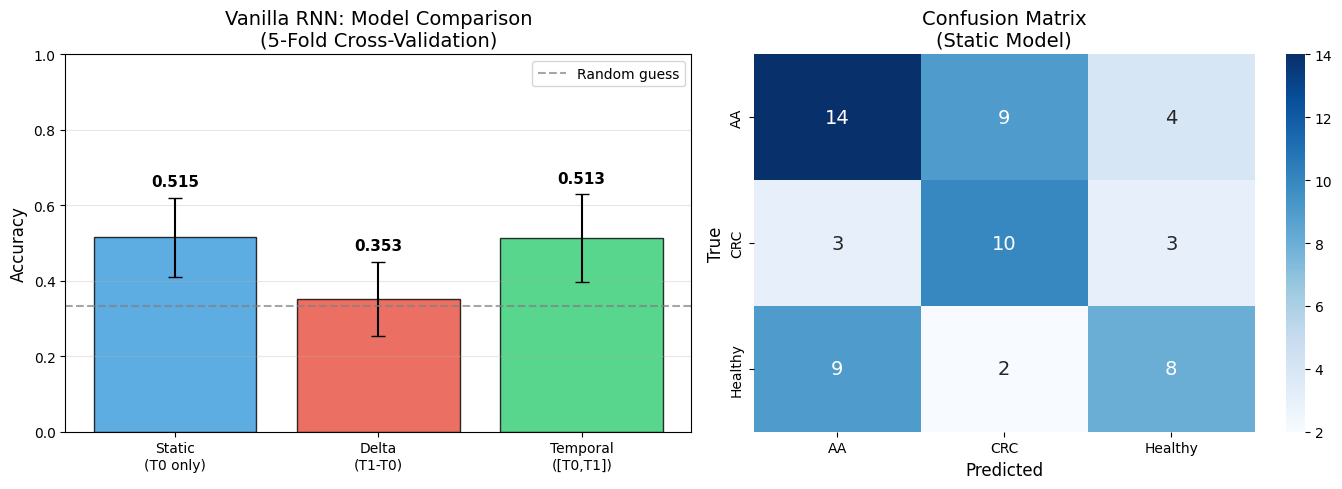

In [ ]:
# Visualization
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Bar plot comparison
modes = ['static', 'delta', 'temporal']
means = [results[m]['mean_acc'] for m in modes]
stds = [results[m]['std_acc'] for m in modes]

colors = ['#3498db', '#e74c3c', '#2ecc71']
x_pos = np.arange(len(modes))

bars = axes[0].bar(x_pos, means, yerr=stds, capsize=5, color=colors, alpha=0.8, edgecolor='black')
axes[0].set_xticks(x_pos)
axes[0].set_xticklabels(['Static\n(T0 only)', 'Delta\n(T1-T0)', 'Temporal\n([T0,T1])'])
axes[0].set_ylabel('Accuracy', fontsize=12)
axes[0].set_title('Vanilla RNN: Model Comparison\n(5-Fold Cross-Validation)', fontsize=14)
axes[0].set_ylim(0, 1)
axes[0].axhline(y=1/len(class_names), color='gray', linestyle='--', label='Random guess', alpha=0.7)
axes[0].legend(loc='upper right')
axes[0].grid(axis='y', alpha=0.3)

# Add values on bars
for bar, mean, std in zip(bars, means, stds):
    axes[0].text(bar.get_x() + bar.get_width()/2, mean + std + 0.03,
                 f'{mean:.3f}', ha='center', fontsize=11, fontweight='bold')

# 2. Confusion matrix for best model
best_mode = max(modes, key=lambda m: results[m]['mean_acc'])
cm = confusion_matrix(results[best_mode]['all_targets'], results[best_mode]['all_preds'])

sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=class_names, yticklabels=class_names, ax=axes[1],
            annot_kws={"size": 14})
axes[1].set_xlabel('Predicted', fontsize=12)
axes[1].set_ylabel('True', fontsize=12)
axes[1].set_title(f'Confusion Matrix\n({best_mode.capitalize()} Model)', fontsize=14)

plt.tight_layout()
plt.show()

In [ ]:
# Classification Report
best_mode = max(modes, key=lambda m: results[m]['mean_acc'])

print(f"\nClassification Report ({best_mode.capitalize()} Model):")
print("="*55)
print(classification_report(
    results[best_mode]['all_targets'],
    results[best_mode]['all_preds'],
    target_names=class_names
))


Classification Report (Static Model):
              precision    recall  f1-score   support

          AA       0.54      0.52      0.53        27
         CRC       0.48      0.62      0.54        16
     Healthy       0.53      0.42      0.47        19

    accuracy                           0.52        62
   macro avg       0.52      0.52      0.51        62
weighted avg       0.52      0.52      0.51        62



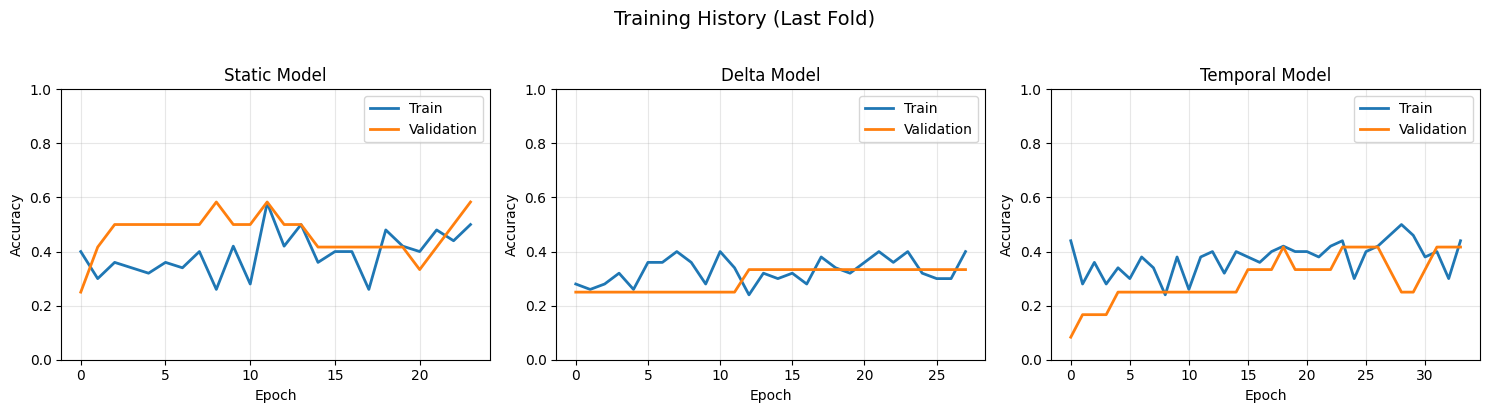

In [ ]:
# Training History (from last fold)
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for idx, mode in enumerate(['static', 'delta', 'temporal']):
    history = results[mode]['histories'][-1]  # Last fold

    axes[idx].plot(history['train_acc'], label='Train', linewidth=2)
    axes[idx].plot(history['val_acc'], label='Validation', linewidth=2)
    axes[idx].set_xlabel('Epoch')
    axes[idx].set_ylabel('Accuracy')
    axes[idx].set_title(f'{mode.capitalize()} Model')
    axes[idx].legend()
    axes[idx].grid(True, alpha=0.3)
    axes[idx].set_ylim(0, 1)

plt.suptitle('Training History (Last Fold)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

---
# ΜΕΡΟΣ 11: TOP DISCRIMINATIVE PROTEINS
---

In [ ]:
# Get protein importance from feature selection
scores = feature_selector.scores_[selected_indices]
protein_importance = sorted(
    zip(selected_proteins, scores),
    key=lambda x: x[1],
    reverse=True
)

print("\nTop 20 Most Discriminative Proteins:")
print("="*50)
for i, (protein, score) in enumerate(protein_importance[:20]):
    print(f"{i+1:2d}. {protein:<20} (F-score: {score:.2f})")


Top 20 Most Discriminative Proteins:
 1. MMP12                (F-score: 12.11)
 2. AREG                 (F-score: 11.87)
 3. ITGAV                (F-score: 7.53)
 4. EDA2R                (F-score: 7.33)
 5. HS6ST1               (F-score: 7.00)
 6. APEX1                (F-score: 6.86)
 7. L1CAM                (F-score: 6.82)
 8. PRKRA                (F-score: 6.75)
 9. VEGFC                (F-score: 6.67)
10. WFDC2                (F-score: 6.32)
11. S100A4               (F-score: 6.20)
12. TPMT                 (F-score: 6.03)
13. INPP1                (F-score: 6.03)
14. PDP1                 (F-score: 5.89)
15. FOXO3                (F-score: 5.82)
16. PRTG                 (F-score: 5.80)
17. NELL1                (F-score: 5.77)
18. PFKFB2               (F-score: 5.75)
19. RASSF2               (F-score: 5.65)
20. NBL1                 (F-score: 5.61)


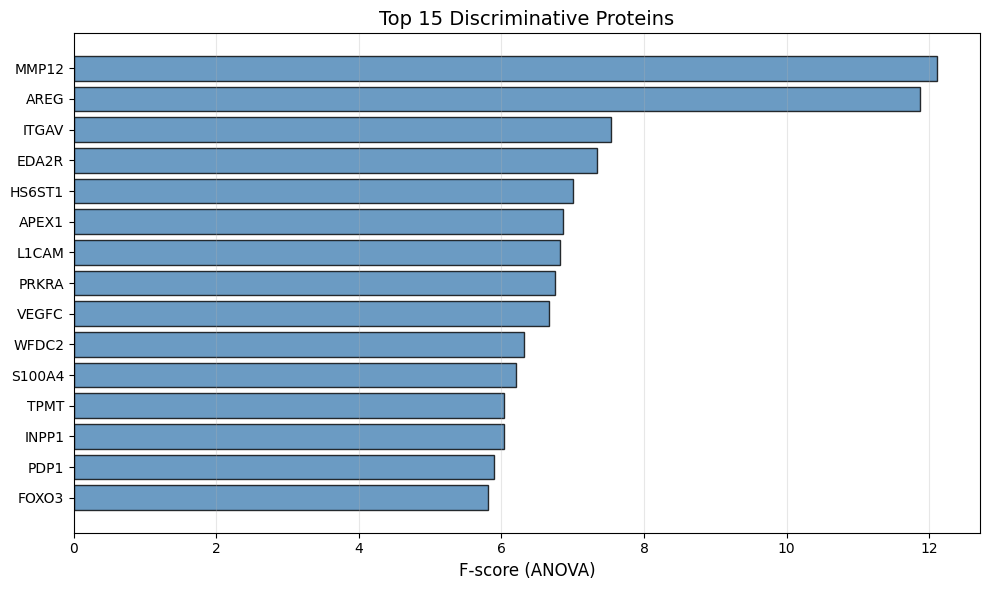

In [ ]:
# Visualize
top_n = 15
top_proteins = [p for p, _ in protein_importance[:top_n]]
top_scores = [s for _, s in protein_importance[:top_n]]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(range(top_n), top_scores[::-1], color='steelblue', alpha=0.8, edgecolor='black')
ax.set_yticks(range(top_n))
ax.set_yticklabels(top_proteins[::-1])
ax.set_xlabel('F-score (ANOVA)', fontsize=12)
ax.set_title('Top 15 Discriminative Proteins', fontsize=14)
ax.grid(axis='x', alpha=0.3)

plt.tight_layout()
plt.show()

---
# ΜΕΡΟΣ 12: SAVE RESULTS
---

In [ ]:
# Save results to CSV
results_df = pd.DataFrame({
    'Model': ['Static', 'Delta', 'Temporal'],
    'Mean_Accuracy': [results['static']['mean_acc'], results['delta']['mean_acc'], results['temporal']['mean_acc']],
    'Std_Accuracy': [results['static']['std_acc'], results['delta']['std_acc'], results['temporal']['std_acc']],
})

# Add fold results
for i in range(Config.N_FOLDS):
    results_df[f'Fold_{i+1}'] = [
        results['static']['fold_results'][i],
        results['delta']['fold_results'][i],
        results['temporal']['fold_results'][i]
    ]

results_df.to_csv('vanilla_rnn_results.csv', index=False)
print("Results saved to 'vanilla_rnn_results.csv'")
display(results_df)

Results saved to 'vanilla_rnn_results.csv'


,Model,Mean_Accuracy,Std_Accuracy,Fold_1,Fold_2,Fold_3,Fold_4,Fold_5
0,Static,0.515385,0.105144,0.615385,0.461538,0.333333,0.583333,0.583333
1,Delta,0.352564,0.097806,0.538462,0.307692,0.250000,0.333333,0.333333
2,Temporal,0.512821,0.116165,0.615385,0.615385,0.583333,0.333333,0.416667


In [ ]:
# Save top proteins
proteins_df = pd.DataFrame({
    'Rank': range(1, len(protein_importance) + 1),
    'Protein': [p for p, _ in protein_importance],
    'F_score': [s for _, s in protein_importance]
})

proteins_df.to_csv('top_proteins_vanilla_rnn.csv', index=False)
print("\nTop proteins saved to 'top_proteins_vanilla_rnn.csv'")
display(proteins_df.head(15))


Top proteins saved to 'top_proteins_vanilla_rnn.csv'


,Rank,Protein,F_score
0,1,MMP12,12.109378
1,2,AREG,11.866981
2,3,ITGAV,7.532688
3,4,EDA2R,7.334444
4,5,HS6ST1,7.003264
5,6,APEX1,6.857357
6,7,L1CAM,6.815330
7,8,PRKRA,6.745584
8,9,VEGFC,6.668576
9,10,WFDC2,6.316217


---
# SUMMARY
---

## Τι Υλοποιήθηκε:

1. **Data Pipeline**
   - Loading από Excel
   - NaN handling (removal + imputation)
   - Feature selection (ANOVA)
   - Normalization

2. **Vanilla RNN Model**
   - Custom VanillaRNNCell implementation
   - Bidirectional support
   - Combined with CNN + Attention

3. **Training**
   - 5-Fold Stratified Cross-Validation
   - Early stopping
   - Class weighting for imbalanced data

4. **Evaluation**
   - Comparison: Static vs Delta vs Temporal
   - Confusion matrices
   - Classification reports

## Vanilla RNN vs LSTM:

| Feature | Vanilla RNN | LSTM |
|---------|-------------|------|
| Equation | `h = tanh(Wx + Wh + b)` | 3 gates + cell state |
| Parameters | Fewer | More (~4x) |
| Memory | Short-term | Long-term |
| Best for | Short sequences | Long sequences |
| Your data (2 timepoints) | ✓ Good | ✓ Good |

## Next Steps:
- Compare with LSTM version
- Get more data for reliable conclusions
- Analyze attention weights for interpretability